# Diffusion with the low-level API

`gropt.diffusion` is a thin layer over `GroptParams`. Building the problem directly lets you add
constraints `DiffParams` does not have, or use the b-value as a constraint rather than an objective.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import gropt
from gropt.diffusion import DiffParams, build_gparams, make_solver
from gropt.plot import get_bval, plot_waves

## The layout

`diff_init` sets up a single-axis spin echo: N from the TE and readout time, the samples under the RF
pulses fixed at 0, and `inv_vec`, the −1 sign after the 180 that the moment and b-value calculations
apply.

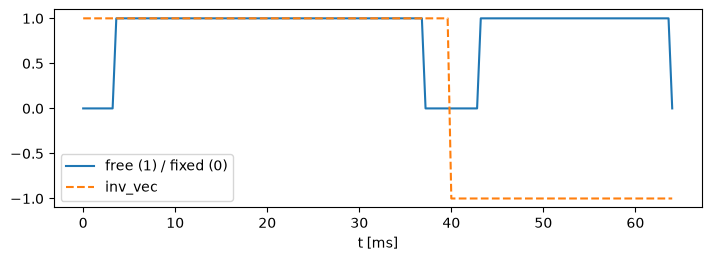

In [2]:
timing = dict(dt=400e-6, TE=80e-3, T_90=3e-3, T_180=5e-3, T_readout=16e-3)

gp = gropt.GroptParams()
gp.diff_init(**timing)

t_ms = np.arange(gp.N) * gp.dt * 1e3
plt.figure(figsize=(7, 2.5), layout='constrained')
plt.plot(t_ms, gp.getvec_fixer(), label='free (1) / fixed (0)')
plt.plot(t_ms, gp.getvec_inv_vec(), '--', label='inv_vec')
plt.xlabel('t [ms]')
plt.legend()
plt.show()

## b-value as a constraint

Moment nulling up to M2, and b ≥ 100 s/mm² (`mode='minval'`; `'setval'` asks for b = 100 ± `tol`):

SolveResult(converged=True, n_iter=91, n_feval=419, X.size=161)
b = 101.0 s/mm^2


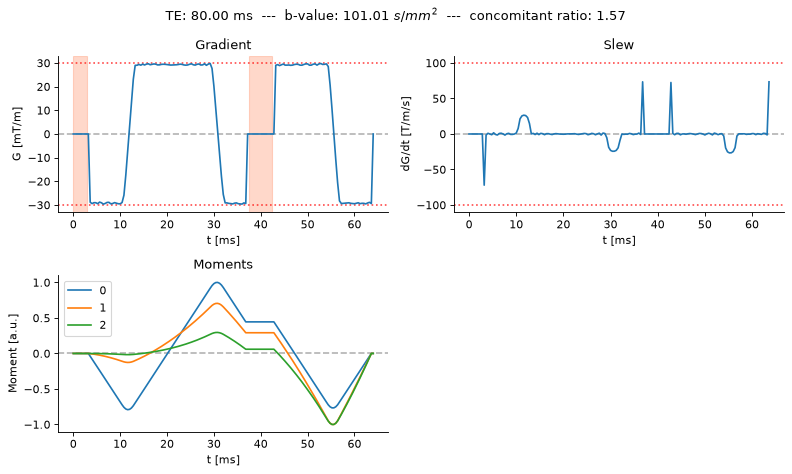

In [3]:
def diffusion_problem():
    gp = gropt.GroptParams()
    gp.diff_init(**timing)
    gp.add_gmax(0.03)
    gp.add_smax(100)
    for order in range(3):
        gp.add_moment(order, 0.0, project=True)
    return gp


gp = diffusion_problem()
gp.add_bvalue(100, mode='minval')
r = gropt.solve(gp)
inv_vec = gp.getvec_inv_vec()
print(r)
print(f'b = {get_bval(r.X, gp.dt, inv_vec):.1f} s/mm^2')
plot_waves(r.X, gp.dt, inv_vec=inv_vec, TE=timing['TE'], gmax=0.03, smax=100, mode='diff',
           params={'MMT': 2, 'T_90': timing['T_90'], 'T_180': timing['T_180']})

## b-value as an objective

`add_bvalue(as_objective=True)` maximizes b instead. With `normalize_obj = True`, `weight_mod` sets the
size of the objective's step relative to the constraints. This is what `DiffParams(bval_mode="obj")`
(the default) builds.

In [4]:
gp = diffusion_problem()
gp.add_bvalue(as_objective=True)
gp.normalize_obj = True
r = gropt.solve(gp)
print(f'converged = {r.converged}, b = {r.bvalue:.1f} s/mm^2')

converged = True, b = 105.5 s/mm^2


The constraint with a target near the maximum, or the objective, may end in a local optimum: b-value
maximization is not convex. The tuned settings in `gropt.diffusion` are the more reliable route to the
highest b-value.

## Starting from a DiffParams

`build_gparams(cfg)` returns the `GroptParams` that `gropt.diffusion.solve` would solve, so you can add
your own constraints and still use the tuned solver settings (`make_solver`). Here the gradient is limited
to 20 mT/m during the first 10 ms:

['Gradient', 'Slew', 'Moment', 'Moment', 'Moment']
converged = True, b = 96.4 s/mm^2


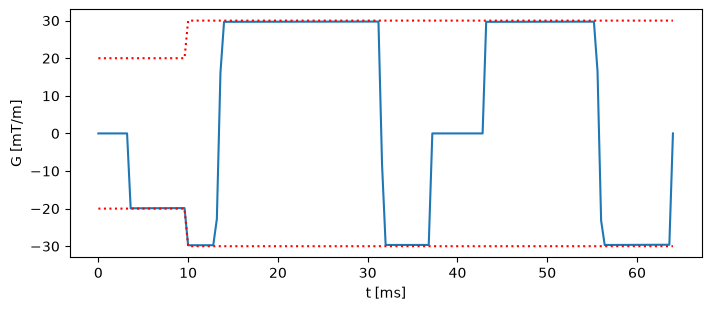

In [5]:
cfg = DiffParams(TE=timing['TE'], T_90=timing['T_90'], T_180=timing['T_180'],
                 T_readout=timing['T_readout'], dt=timing['dt'], gmax=0.03, smax=100.0, MMT=2)
gp, start_idx, weights = build_gparams(cfg)
print(gp.get_op_names())

gmax_vec = np.full(gp.N, 0.03)
gmax_vec[:int(10e-3 / gp.dt)] = 0.02
gp.add_gmax_vec(gmax_vec)

solver = make_solver()   # the default recipe's settings
r = solver.solve(gp)
print(f'converged = {r.converged}, b = {r.bvalue:.1f} s/mm^2')

t_ms = np.arange(gp.N) * gp.dt * 1e3
plt.figure(figsize=(7, 3), layout='constrained')
plt.plot(t_ms, r.X * 1e3)
plt.plot(t_ms, gmax_vec * 1e3, ':r')
plt.plot(t_ms, -gmax_vec * 1e3, ':r')
plt.xlabel('t [ms]')
plt.ylabel('G [mT/m]')
plt.show()